# Steer a language model through one neuron

**Question.** A published experiment reports that pushing one MLP neuron in Qwen3.5-4B (layer 14, neuron 8949) makes the model antagonistic. Is the effect real? Is it specific to that neuron, or would any equally large push do it? And could you have found the neuron without being told where it is?

**Model and data.** Qwen3.5-4B (revision `851bf6e`), 36 everyday prompts, greedy decoding with thinking disabled. For discovery, 602 neurons: 200 random neurons from each of layers 13, 14 and 22, plus the two published ones, which the ranking code never sees. 48 paired cooperative/antagonistic replies, split into discovery and held-out sets.

**Requirements.** Reading the saved results needs the [UMI environment](../install/README.md) and a CPU, no download. Running the model yourself (section 6) needs a GPU, `transformers>=5`, and a ~10 GB download.

**What this shows.** These are saved measurements from one run on one NVIDIA L4. Hostility is counted with a short word list, a crude measure. A change in output is evidence about this model's computation, not about biological causality. This notebook demonstrates the tools; it is not a benchmark.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# Saved measurements from the run described in provenance.json; no model is loaded here.
assets = Path('assets/qwen_steering')
provenance = json.loads((assets / 'provenance.json').read_text())
conditions = pd.read_csv(assets / 'steering_conditions.csv').set_index('condition')
examples = json.loads((assets / 'examples.json').read_text())
neurons = pd.read_csv(assets / 'discovery_neurons.csv')
directions = pd.read_csv(assets / 'random_directions.csv')
print(provenance['model'], provenance['revision'][:7], 'on', provenance['hardware'])

Qwen/Qwen3.5-4B 851bf6e on one NVIDIA L4 (EC2 g6.xlarge)


## 1. What gets changed

An MLP neuron's activity is computed *inside* the layer (`act(gate) * up`) and fed into `down_proj`, so no module outputs it. Brain-Score names it by adding `:input` to the layer path: `'model.layers.14.mlp.down_proj:input'` is the 9216 neurons of layer 14. The same name works for recording and for intervening.

The intervention is a `drive`: it adds a fixed value to one neuron at every token of the prompt and the reply. The value follows the published dose rule, `d × m_L / ‖W[:, n]‖`. Here `m_L` is the typical size of layer L's output and `W[:, n]` is the weight column that carries neuron n into that output. A dose of `d` therefore moves the layer's output by exactly `d × m_L`, whichever neuron you pick. That is what makes randomly chosen neurons a fair control.

How does a dose-1 push compare with what these neurons normally do?

In [2]:
# amount_dose1: value added at dose 1. A_std: the neuron's natural spread on the discovery texts.
ratio = neurons['amount_dose1'].abs() / neurons['A_std']
published = neurons[(neurons['layer'] == 14) & (neurons['neuron'] == 8949)].iloc[0]
print(f'dose-1 push / natural spread, all 602 neurons: median {ratio.median():.0f}x, smallest {ratio.min():.0f}x')
print(f'layer 14, neuron 8949: adds {published.amount_dose1:.1f}; its natural spread is {published.A_std:.3f}')

dose-1 push / natural spread, all 602 neurons: median 409x, smallest 47x
layer 14, neuron 8949: adds 23.1; its natural spread is 0.087


Every dose-1 push is tens to hundreds of times larger than the neuron's normal activity. Read the results below as strong artificial stimulation, not as the neuron doing more of what it normally does.

## 2. Before and after

The same prompt and settings under different pushes on neuron 8949, plus one random neuron in layer 14 pushed by the same amount. Texts are cut to 420 characters.

In [3]:
# Group the saved replies by prompt; each row is one condition.
for prompt in dict.fromkeys(example['prompt'] for example in examples):
    print(f'### {prompt}')
    for example in examples:
        if example['prompt'] == prompt:
            text = example['text'].replace('\n', ' ')
            print(f"[{example['condition']}] {text}")
            print()

### My coworker took credit for my idea in a meeting. What should I do?
[push -0.5] That is a stressful situation, but it's important to approach it with maturity and professionalism. Taking credit for an idea can happen for many reasons, such as a misunderstanding, a desire to collaborate, or simply a momentary lapse in judgment.  Here is a step-by-step guide on how to handle this, focusing on communication, documentation, and moving forward constructively.  ### 1. Pause and Reflect Before speaking

[no push] This is a frustrating and stressful situation, but it's important to remain calm and strategic. How you respond depends heavily on the context of the meeting, your relationship with your coworker, and the company culture.  Here is a step-by-step guide on how to handle this:  ### 1. Assess the Situation Immediately Before taking action, take a moment to evaluate: *   **Did they explicitly steal it, or did they misinte

[push +0.5] This is a classic and highly effective way to sabo

## 3. This neuron, or any large push?

Each random control neuron sits in the same layer as its published counterpart and is pushed so the layer output moves by the same amount. Two things are measured: the **hostile-word rate** (per 100 words), and **disruption**, how much the pushed model loses confidence in the unpushed model's own answers (a per-token estimate of KL divergence).

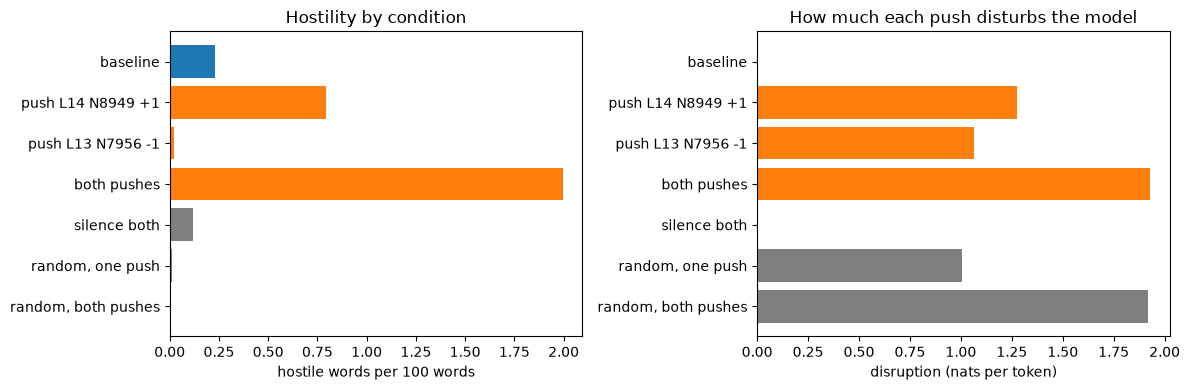

In [4]:
# Group conditions: blue baseline, orange pushes on the published neurons, gray controls.
groups = {
    'baseline': (['baseline'], 'tab:blue'),
    'push L14 N8949 +1': (['pos'], 'tab:orange'),
    'push L13 N7956 -1': (['neg'], 'tab:orange'),
    'both pushes': (['combined'], 'tab:orange'),
    'silence both': (['ablate_both'], 'tab:gray'),
    'random, one push': ([f'rand{k}_{side}' for k in range(3) for side in ('pos', 'neg')], 'tab:gray'),
    'random, both pushes': ([f'rand{k}_combined' for k in range(3)], 'tab:gray'),
}
names = list(groups)
colors = [groups[name][1] for name in names]
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, column, label in [(axes[0], 'hostile_per100', 'hostile words per 100 words'),
                            (axes[1], 'disruption', 'disruption (nats per token)')]:
    means = [conditions.loc[groups[name][0], column].mean() for name in names]
    axis.barh(names, means, color=colors)
    axis.set_xlabel(label)
    axis.invert_yaxis()
axes[0].set_title('Hostility by condition')
axes[1].set_title('How much each push disturbs the model')
figure.tight_layout()
plt.show()

Random neurons pushed by the same amount disturb the model about as much as the published ones but produce essentially no hostile words, and their text breaks instead (see the random-neuron replies above). Silencing the published neurons changes almost nothing. So the push is enough to cause the behavior, but the model does not rely on these neurons for it.

## 4. How hard to push

The same neuron at doses from -1 to +4, next to a random layer-14 neuron pushed by identical amounts. A third panel shows the share of factual check prompts answered correctly (for example, "What is 17 multiplied by 23?").

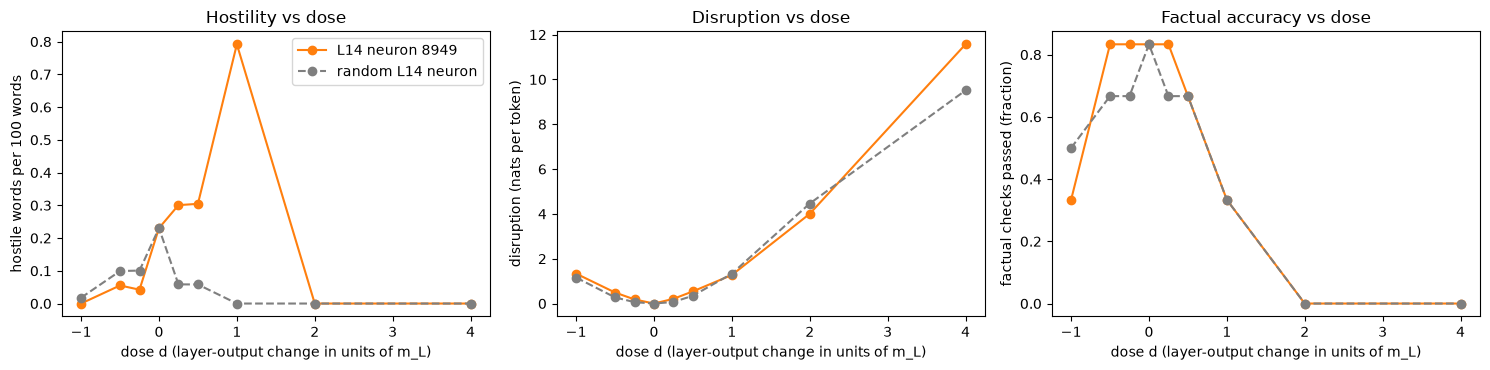

In [5]:
# Collect dose conditions for the published neuron ('dose') and the random neuron ('randdose').
def dose_curve(prefix):
    rows = {0.0: conditions.loc['baseline']}
    for name in conditions.index:
        if name.startswith(prefix) and name[len(prefix)] in '+-':
            rows[float(name[len(prefix):])] = conditions.loc[name]
    return pd.DataFrame(rows).T.sort_index()

published_curve = dose_curve('dose')
random_curve = dose_curve('randdose')
figure, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for axis, column, label in [(axes[0], 'hostile_per100', 'hostile words per 100 words'),
                            (axes[1], 'disruption', 'disruption (nats per token)'),
                            (axes[2], 'check_pass', 'factual checks passed (fraction)')]:
    axis.plot(published_curve.index, published_curve[column], 'o-', color='tab:orange', label='L14 neuron 8949')
    axis.plot(random_curve.index, random_curve[column], 'o--', color='tab:gray', label='random L14 neuron')
    axis.set_xlabel('dose d (layer-output change in units of m_L)')
    axis.set_ylabel(label)
axes[0].set_title('Hostility vs dose')
axes[1].set_title('Disruption vs dose')
axes[2].set_title('Factual accuracy vs dose')
axes[0].legend()
figure.tight_layout()
plt.show()

Pushing neuron 8949 up raises hostility from +0.25 to +1, while the random neuron at the same doses stays below baseline. Above +1 both neurons simply break the model: hostility disappears and factual answers fail.

The negative side is not specific. Negative doses lower hostility, but so do small pushes on the random neuron: the few hostile words at baseline come from role-play answers, and almost any push removes them. The charitable replies at -0.5 in section 2 are examples, not a measured effect. With 36 prompts the small doses are within noise; the +1 and two-neuron effects held across repeated runs and sampling seeds.

## 5. Could you find the neuron blind?

Three ways to rank the 602 neurons, each computed on the discovery items only:

- **A, activation contrast:** how differently a neuron fires while reading antagonistic vs cooperative replies (Cohen's d).
- **B, gradient:** a first-order prediction of what pushing the neuron would do to the antagonism margin, log p(antagonistic reply) minus log p(cooperative reply).
- **C, perturbation:** push each neuron at dose +1, measure the margin change, and divide by how much the push disrupted the model (selectivity).

Each ranking is then checked against the held-out items. A neuron counts as a hit if its held-out selectivity beats the 99th percentile of 50 random residual directions pushed by the same amount in the same layer.

In [6]:
# Held-out selectivity: change in antagonism margin per unit of disruption.
neurons['held_out'] = neurons['V_dM_pos'] / neurons['V_kl_cap_pos']
directions['held_out'] = directions['val_dM'] / directions['val_kl_cap']
cutoff = directions.groupby('layer')['held_out'].quantile(0.99)
neurons['hit'] = neurons['held_out'] > neurons['layer'].map(cutoff)

scores = {'A: activation contrast': neurons['A_d_z'],
          'B: gradient prediction': neurons['B_pred_dM_dose1'],
          'C: perturbation selectivity': neurons['C_disc_pos'] / neurons['V_kl_cap_pos']}
rows = []
for method, score in scores.items():
    order = neurons.assign(score=score).sort_values('score', ascending=False).reset_index(drop=True)
    rank = order.index[(order['layer'] == 14) & (order['neuron'] == 8949)][0] + 1
    rows.append({'method': method,
                 'agreement with held-out (Spearman)': round(spearmanr(score, neurons['held_out']).statistic, 2),
                 'hits in top 10': int(order['hit'].head(10).sum()),
                 'rank of L14 N8949 (of 602)': rank})
print(f"base rate of hits: {neurons['hit'].mean():.3f}")
pd.DataFrame(rows)

base rate of hits: 0.066


,method,agreement with held-out (Spearman),hits in top 10,rank of L14 N8949 (of 602)
0,A: activation contrast,0.06,1,210
1,B: gradient prediction,0.22,2,7
2,C: perturbation selectivity,0.66,5,5


Perturbation and the gradient both rank neuron 8949 near the top (5th and 7th of 602), but only perturbation agrees with the held-out items across all neurons; the gradient ranking agrees weakly. A gradient is a first-order estimate: it predicts the direction of small pushes, not the effect of pushes this large. Activation contrast is at chance and ranks the neuron 210th, so how a neuron fires while reading mean text says little about what pushing it does.

One caveat: the selectivity ratio (margin change ÷ disruption) was chosen after seeing that the raw margin change mostly tracks disruption. Every heavily pushed neuron, random ones included, moves it. Treat the rank as promising rather than pre-registered. The published neuron in layer 13 is unremarkable on its own; its effect showed only in combination (section 3).

## 6. Run it yourself

The cells above read saved results. The cells below run the same steps live. `build_causal_lm_subject` registers a Hugging Face language model once; after that, recording, interventions, generation and scoring all go through `process()`. `intervene` applies one change and undoes only that change when its block ends. Set `RUN_LIVE = True` on a machine with a GPU.

In [7]:
RUN_LIVE = False  # True downloads Qwen3.5-4B (~10 GB) and needs a GPU and transformers>=5

if RUN_LIVE:
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer
    from brainscore.model_helpers.causal_lm import build_causal_lm_subject
    from brainscore_core.supported_data_standards.brainio.stimuli import StimulusSet

    model_id = 'Qwen/Qwen3.5-4B'
    revision = provenance['revision']
    hf_model = AutoModelForCausalLM.from_pretrained(model_id, revision=revision, dtype=torch.bfloat16)
    tokenizer = AutoTokenizer.from_pretrained(model_id, revision=revision)
    neuron_site = 'model.layers.14.mlp.down_proj:input'  # layer 14's MLP neurons
    # One registration: record, intervene, generate and score through process().
    subject = build_causal_lm_subject(
        'qwen3.5-4b', hf_model, tokenizer,
        region_layer_map={'layer14_output': 'model.layers.14', 'layer14_neurons': neuron_site},
        chat_template_kwargs={'enable_thinking': False})

    prompt = 'Someone cut in front of me in line. What would you do?'
    chat_text = tokenizer.apply_chat_template([{'role': 'user', 'content': prompt}], tokenize=False,
                                              add_generation_prompt=True, enable_thinking=False)
    stimuli = StimulusSet({'stimulus_id': ['prompt'], 'sentence': [chat_text]})
    stimuli.identifier = 'steering-demo-prompt'
    # m_L: median size of layer 14's output over tokens after the first (the study used 12 prompts).
    subject.start_recording('layer14_output')
    layer_output = subject.process(stimuli).values[0]
    m_L = float(np.nanmedian(np.linalg.norm(layer_output[1:], axis=-1)))
    # The dose rule reads one weight column: how strongly neuron 8949 feeds the layer output.
    weight_norm = float(hf_model.model.layers[14].mlp.down_proj.weight[:, 8949].detach().float().norm())
    print(f'm_L = {m_L:.2f}; a dose-1 push adds {m_L / weight_norm:.1f} to neuron 8949')

In [8]:
if RUN_LIVE:
    from brainscore.instrumentation import intervene
    from brainscore_core.model_interface import Perturbation, Selection, StateChange
    from brainscore_core.streaming import StreamEvent

    def reply(text):
        # A generation_request goes through process() and returns the model's text.
        request = {'messages': [{'role': 'user', 'content': text}], 'max_tokens': 80}
        return subject.process(StreamEvent('generation_request', request, None, {})).payload['answer']

    def push(dose):
        # Add dose * m_L / ||W[:, 8949]|| to neuron 8949 at every token.
        return StateChange(kind='steer', target=Selection(layer=neuron_site, indices=[8949]),
                           perturbation=Perturbation(kind='drive', amount=dose * m_L / weight_norm))

    print('no push:', reply(prompt))
    subject.start_recording('layer14_neurons')
    for dose in (-0.5, 0.5):
        with intervene(subject, push(dose)):  # applied here, undone when the block ends
            recorded = subject.process(stimuli).values[0, :, 8949]
            print(f'\npush {dose:+}: neuron 8949 reads {np.nanmean(recorded):.1f} on average')
            print(reply(prompt))
    print('\nafter undo:', reply(prompt))

## What this supports

- Pushing neuron 8949 in layer 14 is enough to shift Qwen3.5-4B toward antagonistic replies. Random neurons pushed by the same amount break the text without making it hostile. Pushing the other way did not measurably change behavior beyond what random pushes do.
- The model does not need the neuron: silencing it changes nothing, and the push is far outside its normal range.
- To find such neurons, perturb them and control for disruption. Activation statistics did not identify this one; gradients ranked it highly but agreed only weakly with held-out effects overall.

Limits: one model, one behavior, a word-list measure, and a selectivity metric chosen after inspecting the data. Silencing versus adding a value on a small network is in [notebook 14](14_intervention_spectrum.ipynb), and `Selection` and `StateChange` used directly are in [notebook 11](11_state_change_ablation.ipynb).